## SOAL 1

Jumlah CPU Logic terdeteksi: 4

Worker: 1  | Waktu Eksekusi: 1.3568 detik | Hasil: [7837, 7837, 7837, 7837, 7837, 7837, 7837, 7837]
Worker: 2  | Waktu Eksekusi: 1.0286 detik | Hasil: [7837, 7837, 7837, 7837, 7837, 7837, 7837, 7837]
Worker: 4  | Waktu Eksekusi: 0.7526 detik | Hasil: [7837, 7837, 7837, 7837, 7837, 7837, 7837, 7837]
Worker: 8  | Waktu Eksekusi: 1.0050 detik | Hasil: [7837, 7837, 7837, 7837, 7837, 7837, 7837, 7837]


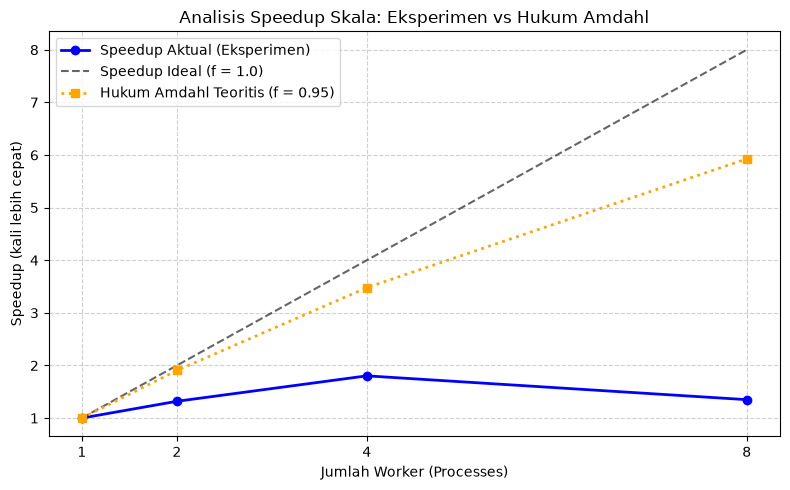

In [1]:
import multiprocessing as mp
import time
import os
import matplotlib.pyplot as plt

# Import fungsi hitung_prima dari file my_functions.py yang baru dibuat
from my_functions import hitung_prima

if __name__ == '__main__':
    # Menyiapkan 8 tugas agar terbagi rata pada 1, 2, 4, dan 8 worker
    daftar_n = [80_000] * 8
    workers = [1, 2, 4, 8]
    waktu_eksekusi = []

    print(f"Jumlah CPU Logic terdeteksi: {os.cpu_count()}\n")

    # Pengujian untuk masing-masing jumlah worker
    for w in workers:
        start = time.perf_counter()
        
        # Di Windows, gunakan mp.Pool secara langsung
        with mp.Pool(processes=w) as pool:
            hasil = pool.map(hitung_prima, daftar_n)
            
        waktu = time.perf_counter() - start
        waktu_eksekusi.append(waktu)
        print(f"Worker: {w:<2} | Waktu Eksekusi: {waktu:.4f} detik | Hasil: {hasil}")

    # Perhitungan Speedup
    waktu_baseline = waktu_eksekusi[0]  # Baseline: 1 worker
    speedup_aktual = [waktu_baseline / t for t in waktu_eksekusi]
    speedup_ideal = workers

    # Kurva Teoritis Hukum Amdahl (misal f = 0.95)
    f = 0.95
    speedup_amdahl = [1 / ((1 - f) + (f / w)) for w in workers]

    # Plotting Grafik
    plt.figure(figsize=(8, 5))
    plt.plot(workers, speedup_aktual, 'o-', color='blue', label='Speedup Aktual (Eksperimen)', linewidth=2)
    plt.plot(workers, speedup_ideal, 'k--', label='Speedup Ideal (f = 1.0)', alpha=0.6)
    plt.plot(workers, speedup_amdahl, 's:', color='orange', label=f'Hukum Amdahl Teoritis (f = {f})', linewidth=2)

    plt.title('Analisis Speedup Skala: Eksperimen vs Hukum Amdahl')
    plt.xlabel('Jumlah Worker (Processes)')
    plt.ylabel('Speedup (kali lebih cepat)')
    plt.xticks(workers)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

Kurva speedup aktual eksperimen tidak persis mengikuti kurva teoritis Hukum Amdahl karena beberapa alasan utama:   
>Keterbatasan Core Fisik CPU: Jika jumlah worker melebihi jumlah core fisik CPU (misalnya 8 worker dijalankan pada CPU 4 core), worker tambahan tidak berjalan secara paralel murni melainkan bergantian (context switching), sehingga percepatan melandai.

>Overhead Pembuatan & Komunikasi Proses: Proses alokasi memori saat membuat proses baru (fork/spawn) serta transfer data antar-proses (pickling/unpickling) membutuhkan waktu eksekusi serial tambahan yang memperlambat total waktu.

>Beban Kerja Latar Belakang (OS & App Lain): Sistem operasi dan aplikasi lain (seperti browser atau IDE) berebut daya komputasi CPU dan memori, sehingga core tidak bekerja 100% khusus untuk worker.   

## SOAL 2

In [2]:
import multiprocessing as mp
import time
# Import kedua fungsi worker dari file terpisah
from worker_functions import worker_queue, worker_value

if __name__ == '__main__':
    N_PROCESSES = 4
    N_NUMBERS = 1_000_000

    print(f"Jumlah Proses : {N_PROCESSES}")
    print(f"Jumlah Angka  : {N_NUMBERS:,} angka acak per proses\n")

    # (a) VERSI A: Message Passing (Queue)
    q = mp.Queue()
    processes_a = []
    start_a = time.perf_counter()

    for _ in range(N_PROCESSES):
        p = mp.Process(target=worker_queue, args=(N_NUMBERS, q))
        processes_a.append(p)
        p.start()

    subtotals = [q.get() for _ in range(N_PROCESSES)]
    total_a = sum(subtotals)

    for p in processes_a:
        p.join()

    waktu_a = time.perf_counter() - start_a

    # (b) VERSI B: Shared Memory (Value + Lock)
    shared_val = mp.Value('d', 0.0)
    lock = mp.Lock()
    processes_b = []
    start_b = time.perf_counter()

    for _ in range(N_PROCESSES):
        p = mp.Process(target=worker_value, args=(N_NUMBERS, shared_val, lock))
        processes_b.append(p)
        p.start()

    for p in processes_b:
        p.join()

    total_b = shared_val.value
    waktu_b = time.perf_counter() - start_b

    # Cetak Hasil Lengkap
    print("--- Hasil Eksekusi ---")
    print(f"[A] Queue (Message Passing)        :")
    print(f"    - Total Hasil Sum : {total_a:,.4f}")
    print(f"    - Waktu Eksekusi  : {waktu_a:.6f} detik\n")

    print(f"[B] Value + Lock (Shared Memory)   :")
    print(f"    - Total Hasil Sum : {total_b:,.4f}")
    print(f"    - Waktu Eksekusi  : {waktu_b:.6f} detik\n")

    selisih = abs(waktu_a - waktu_b)
    tercepat = "Queue (Message Passing)" if waktu_a < waktu_b else "Value + Lock (Shared Memory)"
    print(f"Metode Tercepat: {tercepat} (Selisih: {selisih:.6f} detik)")

Jumlah Proses : 4
Jumlah Angka  : 1,000,000 angka acak per proses

--- Hasil Eksekusi ---
[A] Queue (Message Passing)        :
    - Total Hasil Sum : 1,998,787.9206
    - Waktu Eksekusi  : 0.509279 detik

[B] Value + Lock (Shared Memory)   :
    - Total Hasil Sum : 2,000,114.7517
    - Waktu Eksekusi  : 0.446343 detik

Metode Tercepat: Value + Lock (Shared Memory) (Selisih: 0.062936 detik)


Total Hasil Sum ($\approx 2.000.000$):
>Angka ini tepat karena 4 proses masing-masing menjumlahkan 1 juta angka acak antara $0$ dan $1$ (rata-ratanya $\approx 0.5$, sehingga $4 \times 1.000.000 \times 0.5 = 2.000.000$). Nilai sum antara Versi A dan Versi B sedikit berbeda karena fungsi np.random.rand menghasilkan deret angka acak baru pada setiap eksekusi.

Waktu Eksekusi & Pembandingan:
>Kedua metode berhasil diukur waktunya tanpa terjadi hanging/stuck lagi.   Baris paling bawah secara otomatis membandingkan metode mana yang lebih cepat beserta selisih waktunya.   

## SOAL 3

In [3]:
import multiprocessing as mp
import time
from pc_functions import producer, consumer

if __name__ == '__main__':
    NUM_CONSUMERS = 2
    NUM_ITEMS = 10
    WORKLOAD = 5_000_000  # Beban kerja CPU-bound (5 juta iterasi)
    SENTINEL = None

    items = [WORKLOAD] * NUM_ITEMS

    # Menggunakan multiprocessing.Queue
    task_queue = mp.Queue()
    result_queue = mp.Queue()

    start_time = time.perf_counter()

    # 1. Jalankan Producer Process
    prod = mp.Process(target=producer, args=(task_queue, items, NUM_CONSUMERS, SENTINEL))
    prod.start()

    # 2. Jalankan Consumer Processes
    consumers = []
    for _ in range(NUM_CONSUMERS):
        c = mp.Process(target=consumer, args=(task_queue, result_queue, SENTINEL))
        c.start()
        consumers.append(c)

    # 3. Tunggu hingga semua proses selesai
    prod.join()
    for c in consumers:
        c.join()

    # 4. Ambil hasil komputasi
    results = []
    while not result_queue.empty():
        results.append(result_queue.get())

    end_time = time.perf_counter()

    print(f"Total Tugas Selesai : {len(results)}")
    print(f"Waktu Eksekusi Total : {end_time - start_time:.4f} detik")

Total Tugas Selesai : 10
Waktu Eksekusi Total : 3.3982 detik


Apakah pola kode secara struktur banyak berubah?
>Tidak banyak berubah secara konseptual.

>Persamaan:
>1. Pola utama Producer-Consumer tetap sama, yaitu Producer memproses data/tugas ke dalam antrean (Queue), dan Consumer mengambil tugas tersebut secara terus-menerus (looping) hingga menemukan sinyal penanda selesai (sentinel).

>Perubahan Kunci:
>1. Mengganti threading.Thread menjadi multiprocessing.Process.
>2. Mengganti queue.Queue menjadi multiprocessing.Queue.
>3. Menggunakan struktur if __name__ == '__main__': (serta pemisahan file modul jika di Windows) untuk mencegah eksekusi rekursif saat OS melakukan spawn proses baru.

Apa perbedaan performa yang kalian amati untuk tugas yang CPU-bound?
>1. Versi Threading (Pertemuan 2 - CPU-bound): Pada versi thread, penambahan thread tidak meningkatkan kecepatan (bahkan bisa lebih lambat) karena adanya GIL (Global Interpreter Lock) di CPython.
>2. Versi Multiprocessing (Pertemuan 3 - CPU-bound): Setiap proses yang dibuat memiliki interpreter Python dan alokasi GIL sendiri-sendiri. Hal ini memungkinkan tugas yang bersifat CPU-bound benar-benar dieksekusi secara paralel murni pada multiple core fisik CPU, sehingga menghasilkan penurunan waktu eksekusi (speedup) yang sangat signifikan dibanding versi thread.

## SOAL 4

Skenario nyata memilih Manager() adalah pada aplikasi web interaktif yang membutuhkan berbagi data kompleks antar-proses, seperti caching keranjang belanja (dictionary) atau session user secara dinamis. Manager() memberikan kemudahan pengembangan karena mendukung tipe data native Python yang fleksibel.   Sebaliknya, Value / Array dipilih pada skenario pengolahan citra atau matriks numerik berkinerja tinggi yang melibatkan pemrosesan jutaan angka primitif. Penggunaan shared memory langsung di tingkat C ini memaksimalkan performa dan kecepatan akses tanpa adanya hambatan overhead.   

Trade-off Utama: Manager() unggul dalam kemudahan dan fleksibilitas struktur data namun mengorbankan performa akibat overhead komunikasi server proxy. Sebaliknya, Value/Array memberikan kecepatan eksekusi yang jauh lebih tinggi, tetapi kaku karena terbatas pada tipe data primitif berukuran tetap.